In [ ]:
#%pip install imbalanced-learn

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import laspy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from scipy.spatial import cKDTree
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from imblearn.over_sampling import SMOTE

In [ ]:
path_flo = "C:/Users/flori/Desktop/pa-1_data/kantonal_zurich_1.laz"


las = laspy.read(path_flo)

# List all available attributes in the LAS file
print("Available attributes in LAS file:")
for spec in las.point_format.dimension_names:
    print("-", spec)


df = pd.DataFrame({
    "X": np.array(las.x),
    "Y": np.array(las.y),
    "Z": np.array(las.z),
    "Intensity": np.array(las.intensity),
    "Classification": np.array(las.classification)
})


# total number of points
print("\nTotal number of points:\n", len(df))

display(df["Classification"].value_counts())

Available attributes in LAS file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points:
 6344277


Classification
2     3479116
6     1604924
17     618695
1      382191
3      155665
5       43839
4       31926
15      20122
7        7799
Name: count, dtype: int64

#### PyTorch

In [3]:
# === Load LAS file ===
las = laspy.read(path_flo)

# Compute ground height (approximate lowest Z value)
ground_height = np.min(las.z)

# === Extract features (updated for this file) ===
X = np.vstack((
    las.x, 
    las.y, 
    las.z, 
    las.intensity, 
    las.return_number,  
    las.number_of_returns,  
    las.z - ground_height,        # Height above ground
    las.scan_angle                # Updated feature!
)).T.astype(np.float32)

# === Extract and map labels ===
unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

# === Balance classes (undersample) ===
min_class_count = min(np.bincount(y))
balanced_X, balanced_y = [], []
for class_label in np.unique(y):
    class_indices = np.where(y == class_label)[0]
    sampled_indices = resample(class_indices, replace=True, n_samples=min_class_count, random_state=42)
    balanced_X.append(X[sampled_indices])
    balanced_y.append(y[sampled_indices])

X = np.vstack(balanced_X)
y = np.hstack(balanced_y)

# === Normalize features ===
scaler = StandardScaler()
X = scaler.fit_transform(X)

# === Train-test split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# === Define model (same as before) ===
class PointCloudNet(nn.Module):
    def __init__(self, input_size, num_classes):
        super(PointCloudNet, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc4 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)

    def forward(self, x):
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.relu(self.bn2(self.fc2(x)))
        x = self.relu(self.bn3(self.fc3(x)))
        x = self.dropout(x)
        x = self.fc4(x)
        return x

# === Initialize and train model ===
input_size = X_train.shape[1]
num_classes = len(unique_labels)
model = PointCloudNet(input_size, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

# === Training loop ===
num_epochs = 100
for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    scheduler.step()
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}")

# === Evaluate ===
with torch.no_grad():
    test_outputs = model(X_test)
    predicted = torch.argmax(test_outputs, axis=1)
    accuracy = (predicted == y_test).float().mean()
    print(f"Test Accuracy: {accuracy:.4f}")

Epoch [5/100], Loss: 1.5383
Epoch [10/100], Loss: 1.3075
Epoch [15/100], Loss: 1.2221
Epoch [20/100], Loss: 1.1595
Epoch [25/100], Loss: 1.1268
Epoch [30/100], Loss: 1.0977
Epoch [35/100], Loss: 1.0822
Epoch [40/100], Loss: 1.0693
Epoch [45/100], Loss: 1.0608
Epoch [50/100], Loss: 1.0561
Epoch [55/100], Loss: 1.0515
Epoch [60/100], Loss: 1.0488
Epoch [65/100], Loss: 1.0459
Epoch [70/100], Loss: 1.0451
Epoch [75/100], Loss: 1.0441
Epoch [80/100], Loss: 1.0430
Epoch [85/100], Loss: 1.0428
Epoch [90/100], Loss: 1.0420
Epoch [95/100], Loss: 1.0430
Epoch [100/100], Loss: 1.0414
Test Accuracy: 0.6510


#### Tensorflow

In [ ]:
# Compute ground height (approximate lowest Z value)
ground_height = np.min(las.z)

# === Extract features ===
X = np.vstack((
    las.x,
    las.y,
    las.z,
    las.intensity,
    las.return_number,
    las.number_of_returns,
    las.z - ground_height,        # Height above ground
    las.scan_angle                # Already updated!
)).T.astype(np.float32)

# === Extract and map labels ===
unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

# === Standardize Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Apply SMOTE for Balancing Classes ===
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

# sample
X_sampled, y_sampled = resample(X_resampled, y_resampled, n_samples=500_000, random_state=42)

# === Train-test split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_sampled, y_sampled, test_size=0.2, random_state=42, stratify=y_sampled
)

# === Convert to TensorFlow tensors ===
X_train = tf.convert_to_tensor(X_train, dtype=tf.float32)
X_test = tf.convert_to_tensor(X_test, dtype=tf.float32)
y_train = tf.convert_to_tensor(y_train, dtype=tf.int32)
y_test = tf.convert_to_tensor(y_test, dtype=tf.int32)

# === Build improved Keras model ===
input_size = X.shape[1]
num_classes = len(unique_labels)

model = models.Sequential([
    layers.Input(shape=(input_size,)),
    
    layers.Dense(128),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    
    layers.Dense(256),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Dense(256),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Dense(128),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# === Compile model ===
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === Set callbacks ===
lr_scheduler = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
early_stopping = callbacks.EarlyStopping(patience=15, restore_best_weights=True)

# === Train model ===
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=128,
    callbacks=[lr_scheduler, early_stopping],
    verbose=2
)

# === Evaluate ===
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy:.4f}")

Epoch 1/30
3125/3125 - 13s - 4ms/step - accuracy: 0.7169 - loss: 0.7627 - val_accuracy: 0.7817 - val_loss: 0.5793 - learning_rate: 1.0000e-03
Epoch 2/30
3125/3125 - 12s - 4ms/step - accuracy: 0.7688 - loss: 0.6154 - val_accuracy: 0.8087 - val_loss: 0.5098 - learning_rate: 1.0000e-03
Epoch 3/30
3125/3125 - 21s - 7ms/step - accuracy: 0.7838 - loss: 0.5746 - val_accuracy: 0.8157 - val_loss: 0.4919 - learning_rate: 1.0000e-03
Epoch 4/30
3125/3125 - 13s - 4ms/step - accuracy: 0.7923 - loss: 0.5503 - val_accuracy: 0.8219 - val_loss: 0.4655 - learning_rate: 1.0000e-03
Epoch 5/30
3125/3125 - 10s - 3ms/step - accuracy: 0.7976 - loss: 0.5343 - val_accuracy: 0.8294 - val_loss: 0.4471 - learning_rate: 1.0000e-03
Epoch 6/30
3125/3125 - 11s - 3ms/step - accuracy: 0.8024 - loss: 0.5234 - val_accuracy: 0.8293 - val_loss: 0.4462 - learning_rate: 1.0000e-03
Epoch 7/30
3125/3125 - 10s - 3ms/step - accuracy: 0.8049 - loss: 0.5125 - val_accuracy: 0.8301 - val_loss: 0.4470 - learning_rate: 1.0000e-03
Epoch 

##### Test model on new file

In [9]:
path_flo_2 = "C:/Users/flori/Desktop/pa-1_data/kantonal_zurich_2.laz"

# === Step 1: Load new LAS file ===
las_2 = laspy.read(path_flo_2)

# === Step 2: Compute features ===
ground_height_2 = np.min(las_2.z)

X_new = np.vstack((
    las_2.x,
    las_2.y,
    las_2.z,
    las_2.intensity,
    las_2.return_number,
    las_2.number_of_returns,
    las_2.z - ground_height_2,
    las_2.scan_angle
)).T.astype(np.float32)

# === Step 3: Standardize features using training scaler ===
X_new_scaled = scaler.transform(X_new)

# === Step 4: Predict with trained model ===
X_new_tensor = tf.convert_to_tensor(X_new_scaled, dtype=tf.float32)
y_pred_probs = model.predict(X_new_tensor, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# === Step 5 (optional): Map back to original class labels ===
# Inverse label_map to recover original class IDs (e.g. 2, 6, 17, etc.)
inv_label_map = {v: k for k, v in label_map.items()}
y_pred_original = np.array([inv_label_map[p] for p in y_pred])

In [11]:
# List all available attributes in the LAS file
print("Available attributes in LAS file:")
for spec in las_2.point_format.dimension_names:
    print("-", spec)


df = pd.DataFrame({
    "X": np.array(las_2.x),
    "Y": np.array(las_2.y),
    "Z": np.array(las_2.z),
    "Intensity": np.array(las_2.intensity),
    "Classification": np.array(las_2.classification)
})


# total number of points
print("\nTotal number of points:\n", len(df))

display(df["Classification"].value_counts())

Available attributes in LAS file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points:
 7142798


Classification
2     3606443
6     2312505
5      823094
4      197726
1      137979
3       48155
7        9758
17       7138
Name: count, dtype: int64

**Report**

✅ Accuracy on new data: 0.6916

📊 Classification Report:


c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

     Class 1     0.0000    0.0000    0.0000    137979
     Class 2     0.9308    0.7404    0.8247   3606443
     Class 3     0.0000    0.0000    0.0000     48155
     Class 4     0.0000    0.0000    0.0000    197726
     Class 5     0.0000    0.0000    0.0000    823094
     Class 6     0.5311    0.9816    0.6893   2312505
     Class 7     0.0000    0.0000    0.0000      9758
    Class 17     0.0000    0.0000    0.0000      7138

    accuracy                         0.6916   7142798
   macro avg     0.1827    0.2152    0.1892   7142798
weighted avg     0.6419    0.6916    0.6396   7142798



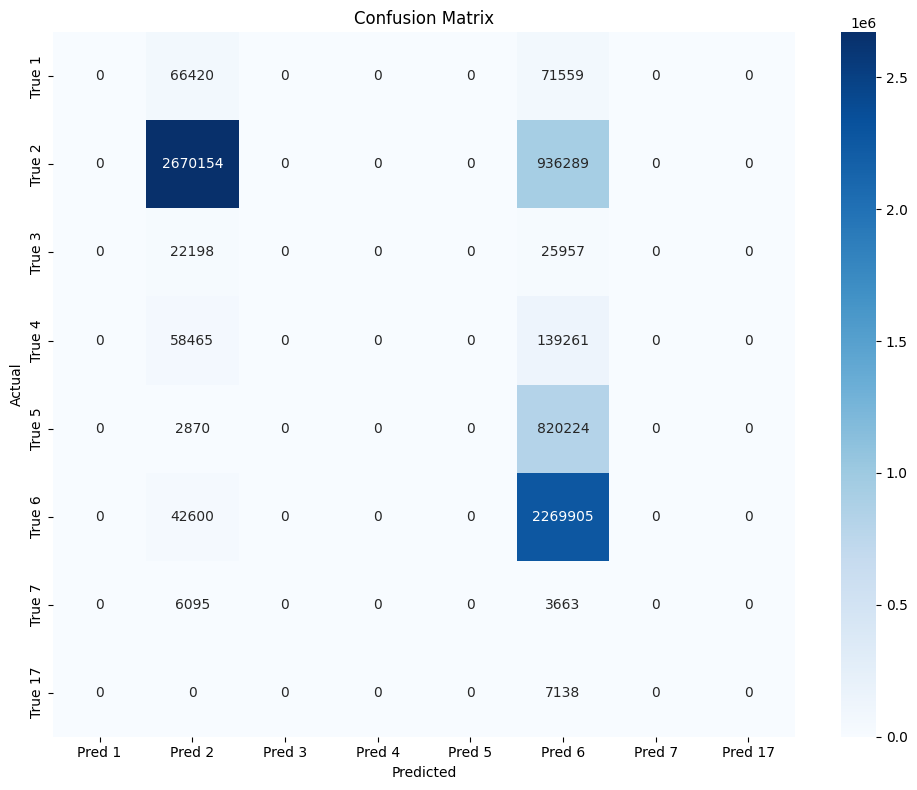

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# === Filter out only those labels that were seen during training ===
valid_indices = [i for i, cls in enumerate(las_2.classification) if cls in label_map]
y_true_new = np.array([label_map[las_2.classification[i]] for i in valid_indices])
y_pred_new = y_pred[valid_indices]

# === Accuracy ===
acc = accuracy_score(y_true_new, y_pred_new)
print(f"✅ Accuracy on new data: {acc:.4f}")

# === Classification report ===
print("\n📊 Classification Report:")
# Determine actual unique labels in the evaluation set
labels_present = sorted(np.unique(y_true_new))

# Print classification report only for present classes
print(classification_report(
    y_true_new,
    y_pred_new,
    labels=labels_present,
    target_names=[f"Class {inv_label_map[i]}" for i in labels_present],
    digits=4
))


# === Confusion matrix ===
cm = confusion_matrix(y_true_new, y_pred_new, labels=labels_present)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"Pred {inv_label_map[i]}" for i in labels_present],
            yticklabels=[f"True {inv_label_map[i]}" for i in labels_present])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

